# EDA Task 1: Lexical Normalization

Data normalisasi untuk T5/ByT5: MultiLexNorm++ (tweet), CONDA (chat Dota 2), NoisyHate (penyamaran nyata), augmentasi penyamaran sintetis.

## Setup

In [1]:
# Imports and Paths
import csv
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo = Path.cwd()
while not (repo / "pyproject.toml").exists():
    repo = repo.parent

RAW = repo / "data" / "raw"
PROC = repo / "data" / "processed" / "task_1"
ANN = repo / "data" / "annotations" / "task_1"
DELIM, SEPA = " | ", "[SEPA]"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)

In [2]:
# Plot Style
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#b4b2ab"]
INK, MUTED, GRID = "#0b0b0b", "#6b6a65", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED,
    "legend.frameon": False,
})

In [3]:
# Loaders
def read_tsv(path):
    """file tsv -> DataFrame (tanpa quoting, kolom string)"""
    return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, quoting=csv.QUOTE_NONE)


def read_norm(path):
    """file .norm -> list kalimat, tiap kalimat list (raw, norm)"""
    sents = []
    for block in path.read_text(encoding="utf-8").strip().split("\n\n"):
        pairs = []
        for line in block.splitlines():
            parts = line.split("\t")
            pairs.append((parts[0], parts[1] if len(parts) > 1 else ""))
        sents.append(pairs)
    return sents


def slots(s):
    return s.split(DELIM) if s else []

## 1. Sumber Data

| Dataset | Isi | Sumber | Peran di Task 1 |
| --- | --- | --- | --- |
| MultiLexNorm++ (en) | Tweet ber-token dengan pasangan normalisasi per token | `hadung1802/mlnorm-resources` (Hugging Face) | Data latih, dev, test |
| CONDA | Chat Dota 2, label intent per baris dan slot per token | `usydnlp/CONDA` (GitHub) | Data latih (label silver), dev, benchmark |
| NoisyHate | Komentar toksik versi asli dan versi disamarkan manusia | `NoisyHate/Noisy_Hate_Data` (Hugging Face) | Benchmark penyamaran nyata |
| Augmentasi | Penyamaran sintetis dari MLN dan CONDA | `src/task_1/prepare/s6_augment.py` | Data latih, dev, benchmark penyamaran |

Data asli disimpan di `data/raw/` (tidak masuk git, cara unduh di README root).
Hasil olahan di `data/processed/task_1/`, label manual di `data/annotations/task_1/`.

## 2. MultiLexNorm++

In [4]:
# MLN Statistics
def change_type(raw, norm):
    if raw == norm:
        return "tetap"
    if norm == "":
        return "merge (N->1)"
    if " " in norm:
        return "split (1->N)"
    return "ganti (1->1)"


mln = {s: read_norm(RAW / "multilexnorm" / "en" / f"{s}.norm") for s in ["train", "dev", "test"]}
rows = []
for split, sents in mln.items():
    pairs = [p for s in sents for p in s]
    types = Counter(change_type(r, n) for r, n in pairs)
    rows.append({"split": split, "kalimat": len(sents), "token": len(pairs),
                 "token berubah %": 100 * (len(pairs) - types["tetap"]) / len(pairs),
                 "kalimat berubah %": 100 * np.mean([any(r != n for r, n in s) for s in sents]),
                 "median token/kalimat": np.median([len(s) for s in sents]),
                 **{k: types[k] for k in ["ganti (1->1)", "split (1->N)", "merge (N->1)"]}})
pd.DataFrame(rows).set_index("split")

,kalimat,token,token berubah %,kalimat berubah %,median token/kalimat,ganti (1->1),split (1->N),merge (N->1)
split,,,,,,,,
train,2360,35216,7.570,56.144,14.0,2346,307,13
dev,590,9169,6.904,55.424,15.0,534,98,1
test,1967,29421,7.899,58.007,14.0,2045,262,17


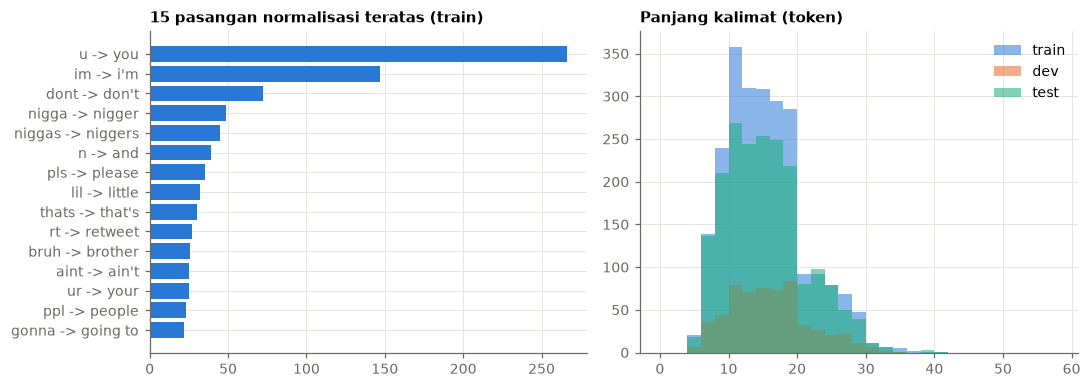

In [5]:
# MLN Top Pairs and Lengths
changed = Counter((r, n) for s in mln["train"] for r, n in s if r != n)
top = changed.most_common(15)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].barh([f"{r} -> {n or '(kosong)'}" for (r, n), _ in top], [c for _, c in top], color=SERIES[0])
axes[0].set_title("15 pasangan normalisasi teratas (train)")
for (split, sents), color in zip(mln.items(), SERIES):
    axes[1].hist([len(s) for s in sents], bins=range(0, 60, 2), alpha=0.55, label=split, color=color)
axes[1].set_title("Panjang kalimat (token)")
axes[1].legend()
fig.tight_layout()

## 3. CONDA

In [6]:
# CONDA Raw Rows
conda = {s: pd.read_csv(RAW / "conda" / "data" / f"CONDA_{s}.csv", dtype=str, keep_default_na=False)
         for s in ["train", "valid", "test"]}
rows = []
for split, df in conda.items():
    lines = [p.strip() for u in df["utterance"] for p in u.split(SEPA) if p.strip()]
    rows.append({"csv": split, "baris": len(df), "match": df["matchId"].nunique(), "baris chat": len(lines),
                 "chat/baris": len(lines) / len(df), "token/chat median": np.median([len(x.split()) for x in lines]),
                 "chat 1 token %": 100 * np.mean([len(x.split()) == 1 for x in lines]),
                 "berlabel": split != "test"})
pd.DataFrame(rows).set_index("csv")

,baris,match,baris chat,chat/baris,token/chat median,chat 1 token %,berlabel
csv,,,,,,,
train,26921,1911,37343,1.387,2.0,44.445,True
valid,8974,1778,12581,1.402,2.0,45.155,True
test,8974,1781,12544,1.398,2.0,44.491,False


toksik (E+I): 0.195


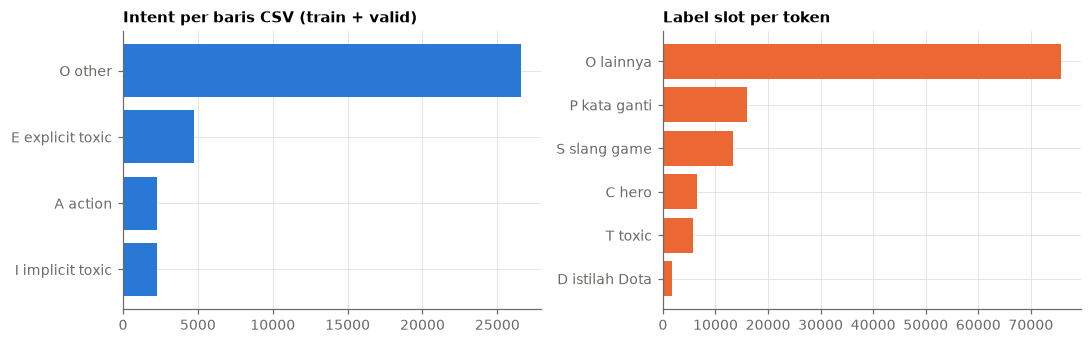

In [7]:
# CONDA Labels
labeled = pd.concat([conda["train"], conda["valid"]])
slot_re = re.compile(r"(.*?) \((\w+)\), ")
slot_counts = Counter(lab for s in labeled["slotTokens"] for _, lab in slot_re.findall(s) if lab != "SEPA")
intent_names = {"E": "E explicit toxic", "I": "I implicit toxic", "A": "A action", "O": "O other"}
slot_names = {"T": "T toxic", "C": "C hero", "D": "D istilah Dota", "S": "S slang game", "P": "P kata ganti",
              "O": "O lainnya"}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
ic = labeled["intentClass"].value_counts()
axes[0].barh([intent_names[k] for k in ic.index][::-1], ic.values[::-1], color=SERIES[0])
axes[0].set_title("Intent per baris CSV (train + valid)")
sc = pd.Series(slot_counts).sort_values()
axes[1].barh([slot_names.get(k, k) for k in sc.index], sc.values, color=SERIES[1])
axes[1].set_title("Label slot per token")
fig.tight_layout()
print("toksik (E+I):", f"{labeled['intentClass'].isin(['E', 'I']).mean():.3f}")

In [8]:
# CONDA Examples
labeled.groupby("intentClass").head(3)[["intentClass", "utterance", "slotTokens"]].sort_values("intentClass")

,intentClass,utterance,slotTokens
8,A,gg [SEPA] report my team rat [SEPA] please,"gg (S), [SEPA] (SEPA), report (S), my (P), team (O), rat (S), [SEPA] (SEPA), please (O),"
18,A,g?,"g (O),"
20,A,Pls report sb thanks,"Pls (O), report (S), sb (C), thanks (O),"
5,E,i cant [SEPA] play [SEPA] with 4 trash,"i (P), cant (O), [SEPA] (SEPA), play (O), [SEPA] (SEPA), with (O), 4 (O), trash (O),"
11,E,my arrows [SEPA] always decent [SEPA] fuck u,"my (P), arrows (O), [SEPA] (SEPA), always (O), decent (O), [SEPA] (SEPA), fuck (T), u ..."
25,E,fuyckjerfe,"fuyckjerfe (O),"
9,I,ez mid,"ez (S), mid (S),"
52,I,ez,"ez (S),"
58,I,ez game,"ez (S), game (O),"
0,O,wow!,"wow (O),"


Split CONDA dibuat per match (80/10/10, seed 2026), bukan per baris, karena split asli acak per baris: 1772 dari 1921 match muncul di train dan valid sekaligus.
Baris CSV test CONDA tidak berlabel dan tidak masuk benchmark.

In [9]:
# CONDA Line Split
lines = read_tsv(PROC / "conda" / "lines.tsv")
split_tab = lines.groupby("split").agg(baris_chat=("id", "size"), match=("match_id", "nunique"))
split_tab["unik"] = lines.groupby("split")["raw"].nunique()
split_tab.loc[["train", "dev", "bench"]]

,baris_chat,match,unik
split,,,
train,50427,1537,30163
dev,6012,192,4158
bench,4777,192,3459


## 4. Label Normalisasi CONDA

CONDA tidak punya target normalisasi. Target silver dibuat per tipe token: otomatis (kamus MLN, kata baku, lexicon CONDA), review manusia, usulan LLM per tipe dan per baris, lalu 300 baris dikoreksi manual sebagai gold.

In [10]:
# Label Origin
build = json.loads((PROC / "reports" / "build_stats.json").read_text())
origin = pd.Series(build["label_origin_slots"]).sort_values(ascending=False)
origin_names = {"auto": "aturan otomatis", "mln_review": "kamus MLN + review", "llm_slot": "LLM per baris",
                "llm_type": "LLM per tipe", "gold": "gold manual", "line_override": "koreksi baris"}
display(pd.DataFrame({"slot": origin, "%": 100 * origin / origin.sum()}).rename(index=origin_names))
changed = pd.DataFrame({"baris": build["conda_lines"], "berubah": build["conda_changed_lines"]})
changed["berubah %"] = 100 * changed["berubah"] / changed["baris"]
display(changed.loc[["train", "dev", "bench"]])
print("kesepakatan silver vs gold:", build["gold"])

,slot,%
aturan otomatis,127743,83.899
kamus MLN + review,8989,5.904
LLM per baris,8762,5.755
LLM per tipe,5665,3.721
gold manual,1041,0.684
koreksi baris,58,0.038


,baris,berubah,berubah %
train,50427,9973,19.777
dev,6012,1151,19.145
bench,4777,891,18.652


kesepakatan silver vs gold: {'lines': 300, 'silver_line_agreement': 0.9333, 'silver_slot_agreement': 0.9789}


In [11]:
# Silver Examples
train = read_tsv(PROC / "conda" / "train.tsv")
diff = train[train["src"] != train["tgt"]]
diff.sample(10, random_state=2026)[["raw", "src", "tgt"]]

,raw,src,tgt
35236,ty all,ty | all,thank you | all
23617,ik but the logic,ik | but | the | logic,i know | but | the | logic
41226,cant,cant,can't
16396,weaver mid dont worry,weaver | mid | dont | worry,weaver | mid | don't | worry
29184,congrats,congrats,congratulations
25594,u did fine,u | did | fine,you | did | fine
32107,we gonna report u,we | gonna | report | u,we | going to | report | you
36017,i cant even find words how bad he is,i | cant | even | find | words | how | bad | he | is,i | can't | even | find | words | how | bad | he | is
3198,how do u even play if u DC every 2 sec?,how | do | u | even | play | if | u | dc | every | 2 | sec | ?,how | do | you | even | play | if | you | dc | every | 2 | sec | ?
50233,dont let ur team die alone,dont | let | ur | team | die | alone,don't | let | your | team | die | alone


## 5. Gold CONDA

In [12]:
# Gold Strata
gold = read_tsv(ANN / "line_labels" / "gold_conda.tsv")
gold["silver benar"] = gold["silver"] == gold["gold"]
display(gold.groupby("stratum").agg(baris=("id", "size"), silver_benar=("silver benar", "mean")))
gold[gold["silver"] != gold["gold"]].head(8)[["stratum", "src", "silver", "gold"]]

,baris,silver_benar
stratum,,
changed,90,0.922
game,60,0.917
other,60,0.950
toxic,90,0.944


,stratum,src,silver,gold
0,toxic,gg | wop,gg | wop,gg | wp
15,toxic,wtf | happend,wtf | happend,wtf | happened
27,toxic,ur | fucking | ded | champ,your | fucking | dead | champ,you're | fucking | dead | champ
41,toxic,fail | mid | lachi | retrad | nooob,fail | mid | lachi | retard | noob,fail | mid | alchi | retard | noob
70,toxic,fat | puj | xd,fat | puj | xd,fat | pudge | xd
120,changed,ez | setnry | by | sniper,ez | sentry | by | sniper,easy | sentry | by | sniper
126,changed,i | know | u | love | techies | gus,i | know | you | love | techies | gus,i | know | you | love | techies | guys
134,changed,58 | ez | ? | u | mom | teach | u | ?,58 | ez | ? | you | mom | teach | you | ?,58 | easy | ? | your | mom | teach | you | ?


## 6. Augmentasi Penyamaran

In [13]:
# Augmentation Ops
aug = json.loads((PROC / "reports" / "aug_stats.json").read_text())
display(pd.DataFrame(aug).fillna(0).astype(int))
aug_train = read_tsv(PROC / "augmented" / "train.tsv")
aug_train.groupby("op").head(2)[["op", "src", "tgt"]].sort_values("op")

,bench,dev,train
accent,523,670,1203
drop,406,523,851
leet,512,658,2954
leet_repeat,517,649,600
repeat,548,700,3223
spaced,531,683,1192
symbol,548,699,1858
real,0,0,84


,op,src,tgt
5,accent,@jpaulinel | heheheh | miss | youu | atè | jean | !!,@jpaulinel | heheheh | miss | you | ate | jean | !!
8,accent,rt | @1dalert | : | guys | that | picture | of | zayn | is | old | !! | and | also | y...,rt | @1dalert | : | guys | that | picture | of | zayn | is | old | !! | and | also | y...
49,drop,@bamboomusiclive | hi | coach | !!! | a | gud | evning | to | you | . | mis | u,@bamboomusiclive | hi | coach | !!! | a | good | evening | to | you | . | miss | you
67,drop,@ayu98srivastava | i | couldnt | find | it | . | . | can | u | sed | me | screen shot,@ayu98srivastava | i | couldn't | find | it | . | . | can | you | send | me | screenshot
1,leet,rt | @michael_heaver | : | uk!p | has | had | two | councillors | elected | in | north...,rt | @michael_heaver | : | ukip | has | had | two | councillors | elected | in | north...
2,leet,@kam_maynee | lol | cause | i | said | & | you | woulda | been | falling | right | alo...,@kam_maynee | lol | because | i | said | & | you | would have | been | falling | right...
9,leet_repeat,@vilde_hr | i | literally | love | you | omf9g9g | u | just | made | my | whole | day ...,@vilde_hr | i | literally | love | you | omfg | you | just | made | my | whole | day |...
18,leet_repeat,@minquannn | haha | mq | pls | as | easy | as | do7t7o | for | me | #feedforlife,@minquannn | haha | mq | please | as | easy | as | doto | for | me | #feedforlife
604,real,rt | @tehreelhov | : | rt | if | ur | still | up | becuz | ur | an | hood | a55 | niga,rt | @tehreelhov | : | retweet | if | you're | still | up | because | you're | an | ho...
730,real,suck | my | d1ck,suck | my | dick


## 7. NoisyHate

In [14]:
# NoisyHate
nh = read_tsv(PROC / "noisyhate" / "test.tsv")
n_changed = [sum(a != b for a, b in zip(slots(r.src), slots(r.tgt))) for r in nh.itertuples()]
print("kalimat:", len(nh), "| median slot tersamar:", np.median(n_changed), "| token/kalimat median:",
      np.median([len(slots(s)) for s in nh["src"]]))
pairs = Counter((a, b) for r in nh.itertuples() for a, b in zip(slots(r.src), slots(r.tgt)) if a != b)
pd.DataFrame([{"tersamar": a, "asli": b, "jumlah": c} for (a, b), c in pairs.most_common(12)])

kalimat: 1339 | median slot tersamar: 1.0 | token/kalimat median: 7.0


,tersamar,asli,jumlah
0,trashhh,trash,9
1,looser,loser,9
2,foool,fool,9
3,shot,shoot,8
4,crapp,crap,7
5,as,ass,7
6,blck,black,7
7,loooseeer,loser,7
8,loooser,loser,7
9,daaaaamn,damn,7


## 8. Contoh Data Latih

Input model = prefix `normalize: ` + slot raw ber-delimiter. Target = slot normal ber-delimiter, jumlah slot sama dengan input.

In [15]:
# Training Pairs
sources = {"MLN": PROC / "mln" / "train.tsv", "CONDA": PROC / "conda" / "train.tsv",
           "Augmentasi": PROC / "augmented" / "train.tsv"}
examples = []
for name, path in sources.items():
    df = read_tsv(path)
    df = df[(df["src"] != df["tgt"]) & (df["src"].str.len() < 70)]
    for r in df.sample(3, random_state=7).itertuples():
        examples.append({"sumber": name, "input": "normalize: " + r.src, "target": r.tgt})
pd.DataFrame(examples)

,sumber,input,target
0,MLN,normalize: rt | @memecomik | : | selamat | pagi | .. | congrats | real | madrid,rt | @memecomik | : | selamat | pagi | .. | congratulations | real | madrid
1,MLN,normalize: where | tf | is | my | bestfriend | ?,where | the fuck | is | my | best friend | ?
2,MLN,normalize: juss | hold | on | we | goin | home | http://t.co/jvkdk1awuu,just | hold | on | we | going | home | http://t.co/jvkdk1awuu
3,CONDA,normalize: ur | my | food,your | my | food
4,CONDA,normalize: 2 | spells | noore,2 | spells | more
5,CONDA,normalize: lost | da | game,lost | the | game
6,Augmentasi,normalize: f a s t,fast
7,Augmentasi,normalize: go | mid | and | g*nk | ember | hes | fat,go | mid | and | gank | ember | he's | fat
8,Augmentasi,normalize: 1oo0o1,lol


In [16]:
# Training Mix
mix = {name: len(read_tsv(path)) for name, path in sources.items()}
total = sum(mix.values())
pd.DataFrame({"baris": mix, "%": {k: 100 * v / total for k, v in mix.items()}})

,baris,%
MLN,2360,3.645
CONDA,50427,77.877
Augmentasi,11965,18.478
